# Data Visualization in Python
**MTH1203 – Probability and Statistics | Group Research Assignment (Advent 2026)**
**Uganda Christian University – Faculty of Engineering, Design and Technology**

**Group members:** *('ndahayo dieu est la -M26B13/071')*

This notebook demonstrates the main plot types discussed in our report using **Matplotlib**, **Seaborn**, **Pandas plotting** and **Plotly**.
The dataset is generated in the notebook itself (with a fixed random seed), so the notebook runs anywhere with no downloads and gives the same results every time.

**How to run:** `pip install pandas numpy matplotlib seaborn plotly` then *Kernel → Restart & Run All*.

## 1. Setup

In [31]:
# Import the libraries used in this notebook
import numpy as np                 # numerical work and random numbers
import pandas as pd                # tables (DataFrames) and quick plotting
import matplotlib.pyplot as plt    # the core plotting library
import seaborn as sns              # statistical plots built on Matplotlib

# Plotly is used for interactive charts in Section 10
try:
    import plotly.express as px
    PLOTLY_OK = True
except ImportError:
    PLOTLY_OK = False
    print("Plotly not installed - run: pip install plotly")

# A clean, consistent look for every chart
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
print("Libraries loaded.")

Plotly not installed - run: pip install plotly
Libraries loaded.


## 2. Why we visualize: Anscombe's quartet
Four small datasets that have **almost identical** summary statistics (same mean, variance, correlation and regression line) but look completely different when plotted. This is the strongest argument for always plotting data before trusting numbers alone (Anscombe, 1973).

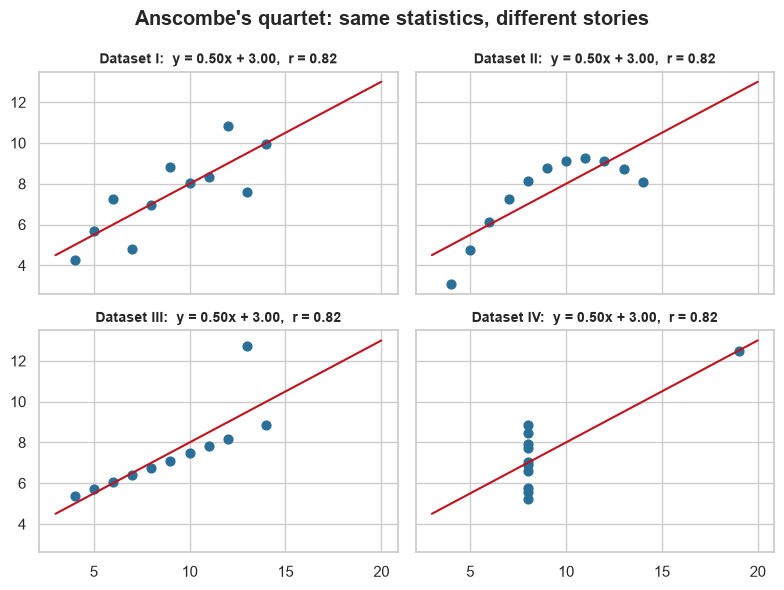

In [48]:
# Anscombe's quartet: the four datasets
x123 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "I":   (x123, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x123, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x123, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8]*7 + [19] + [8]*3, [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}

fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True)
for ax, (name, (x, y)) in zip(axes.ravel(), anscombe.items()):
    slope, intercept = np.polyfit(x, y, 1)          # the same line fits all four!
    r = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, color="#2A6F97", s=40)
    xs = np.array([3, 20])
    ax.plot(xs, slope * xs + intercept, color="#C1121F", lw=1.5)
    ax.set_title(f"Dataset {name}:  y = {slope:.2f}x + {intercept:.2f},  r = {r:.2f}", fontsize=10)
fig.suptitle("Anscombe's quartet: same statistics, different stories", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. The sample dataset
We simulate exam results for **200 first-year students**. Each row is one student. The variables are:

| Variable | Type | Meaning |
|---|---|---|
| `program` | categorical | Degree programme |
| `gender`, `residence` | categorical | Female/Male; On-campus/Off-campus |
| `study_hours` | numerical | Weekly self-study hours |
| `attendance` | numerical | Class attendance (%) |
| `sleep_hours` | numerical | Average nightly sleep |
| `exam_score` | numerical | Final exam mark (%) |

In [33]:
rng = np.random.default_rng(42)     # fixed seed = reproducible results
n = 200

df = pd.DataFrame({
    "student_id": np.arange(1, n + 1),
    "gender": rng.choice(["Female", "Male"], n, p=[0.52, 0.48]),
    "program": rng.choice(["Information Technology", "Computer Science",
                           "Software Engineering", "Networking"], n, p=[0.35, 0.28, 0.22, 0.15]),
    "residence": rng.choice(["On-campus", "Off-campus"], n, p=[0.45, 0.55]),
    "study_hours": rng.normal(12, 4, n).clip(2, 30).round(1),
    "attendance": rng.normal(80, 10, n).clip(40, 100).round(1),
    "sleep_hours": rng.normal(6.5, 1.1, n).clip(3, 10).round(1),
})

# Exam score depends on study hours, attendance and sleep, plus random noise
df["exam_score"] = (5 + 2.0 * df.study_hours + 0.30 * df.attendance
                    + 1.5 * df.sleep_hours + rng.normal(0, 6, n)).clip(0, 100).round(1)

# A second, time-based dataset: weekly average quiz scores for two class sections
weeks = np.arange(1, 13)
weekly = pd.DataFrame({
    "week": weeks,
    "Section A": 52 + 2.0 * weeks + rng.normal(0, 2, 12),
    "Section B": 48 + 2.6 * weeks + rng.normal(0, 2, 12),
}).round(1)

df.head()

,student_id,gender,program,residence,study_hours,attendance,sleep_hours,exam_score
0,1,Male,Software Engineering,On-campus,17.0,84.0,6.0,74.1
1,2,Female,Networking,Off-campus,11.0,80.6,4.9,60.7
2,3,Male,Computer Science,Off-campus,13.5,67.0,7.0,65.1
3,4,Male,Information Technology,On-campus,2.4,79.5,7.0,36.2
4,5,Female,Information Technology,Off-campus,7.4,79.2,4.8,55.9


In [34]:
# Summary statistics for the numerical variables
df[["study_hours", "attendance", "sleep_hours", "exam_score"]].describe().round(2)

,study_hours,attendance,sleep_hours,exam_score
count,200.00,200.00,200.00,200.00
mean,11.74,79.41,6.51,62.00
std,4.23,9.87,1.05,10.88
min,2.00,43.50,3.80,32.40
25%,8.40,73.58,5.90,55.70
50%,11.90,80.05,6.50,61.40
75%,14.60,84.58,7.20,69.18
max,22.20,100.00,9.60,95.70


## 4. Bar chart (comparing categories)
**Use when:** comparing a value (here the mean) across separate categories. Bars must start at zero.

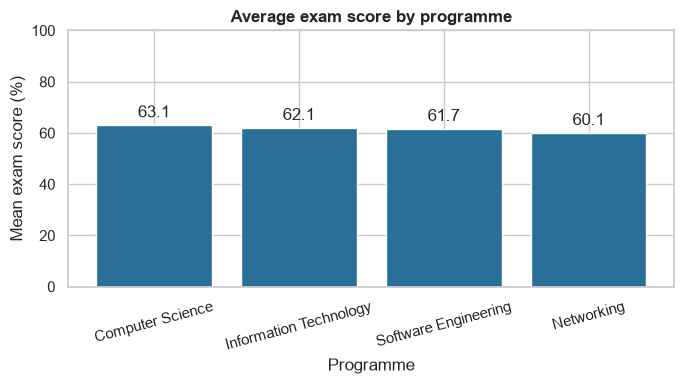

In [35]:
# Mean exam score per programme, sorted from highest to lowest
avg = df.groupby("program")["exam_score"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(avg.index, avg.values, color="#2A6F97")
ax.bar_label(bars, fmt="%.1f", padding=3)           # print the value on each bar
ax.set_title("Average exam score by programme")
ax.set_xlabel("Programme")
ax.set_ylabel("Mean exam score (%)")
ax.set_ylim(0, 100)                                 # honest baseline at zero
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 5. Line chart (change over time)
**Use when:** showing a trend across an ordered variable such as time.

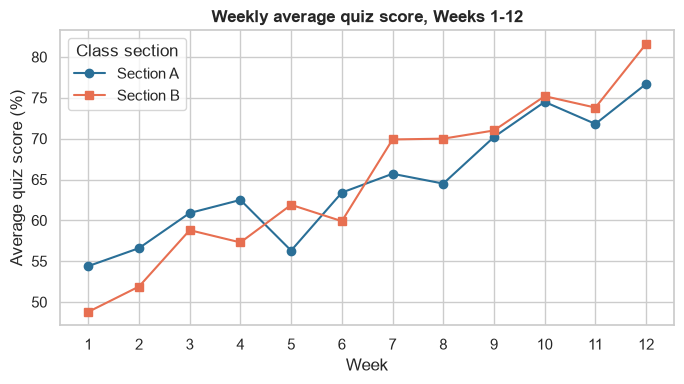

In [36]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(weekly["week"], weekly["Section A"], marker="o", label="Section A", color="#2A6F97")
ax.plot(weekly["week"], weekly["Section B"], marker="s", label="Section B", color="#E76F51")
ax.set_title("Weekly average quiz score, Weeks 1-12")
ax.set_xlabel("Week")
ax.set_ylabel("Average quiz score (%)")
ax.set_xticks(weeks)
ax.legend(title="Class section")
plt.tight_layout()
plt.show()

## 6. Histogram (distribution of one numerical variable)
**Use when:** you want the shape, centre and spread of a single numerical variable.

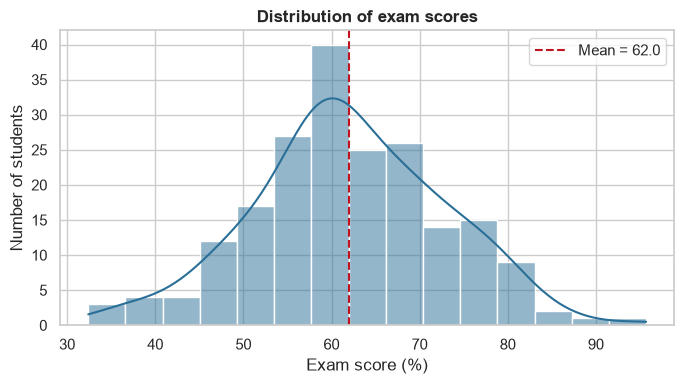

In [37]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["exam_score"], bins=15, kde=True, color="#2A6F97", ax=ax)   # bars + smooth curve
mean_score = df["exam_score"].mean()
ax.axvline(mean_score, color="#C1121F", linestyle="--", label=f"Mean = {mean_score:.1f}")
ax.set_title("Distribution of exam scores")
ax.set_xlabel("Exam score (%)")
ax.set_ylabel("Number of students")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Scatter plot (relationship between two numerical variables)
**Use when:** checking whether two variables are related (correlation, trend, outliers).

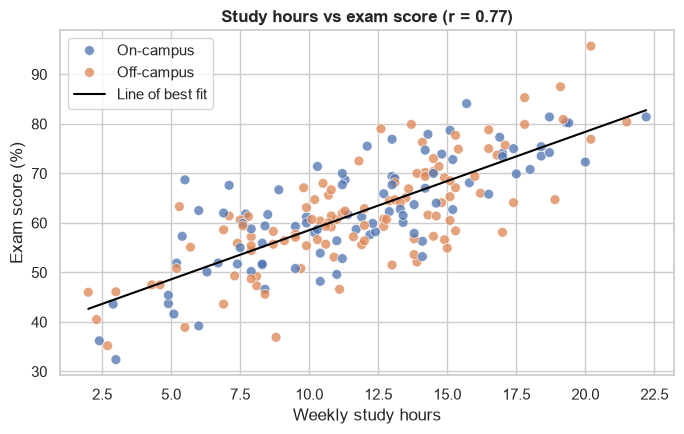

In [38]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=df, x="study_hours", y="exam_score", hue="residence",
                alpha=0.75, s=50, ax=ax)

# Add a straight line of best fit
slope, intercept = np.polyfit(df["study_hours"], df["exam_score"], 1)
xs = np.linspace(df["study_hours"].min(), df["study_hours"].max(), 50)
ax.plot(xs, slope * xs + intercept, color="black", lw=1.5, label="Line of best fit")

r = df["study_hours"].corr(df["exam_score"])       # Pearson correlation coefficient
ax.set_title(f"Study hours vs exam score (r = {r:.2f})")
ax.set_xlabel("Weekly study hours")
ax.set_ylabel("Exam score (%)")
ax.legend(title="")
plt.tight_layout()
plt.show()

## 8. Box plot, pie chart, heatmap
### 8.1 Box plot (compare distributions between groups)
The box shows the median and quartiles (Q1-Q3); whiskers show the typical range; dots are potential outliers.

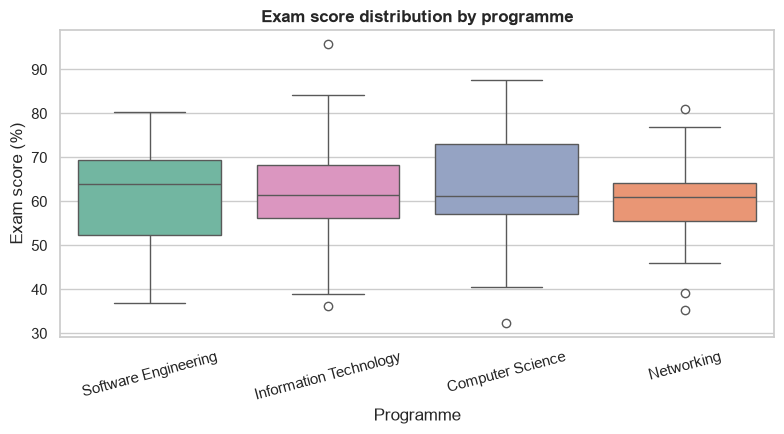

In [39]:
order = df.groupby("program")["exam_score"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="program", y="exam_score", order=order,
            hue="program", palette="Set2", legend=False, ax=ax)
ax.set_title("Exam score distribution by programme")
ax.set_xlabel("Programme")
ax.set_ylabel("Exam score (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 8.2 Pie chart (parts of a whole)
Only suitable for **a few categories (about 5 or fewer)** that add up to 100%.

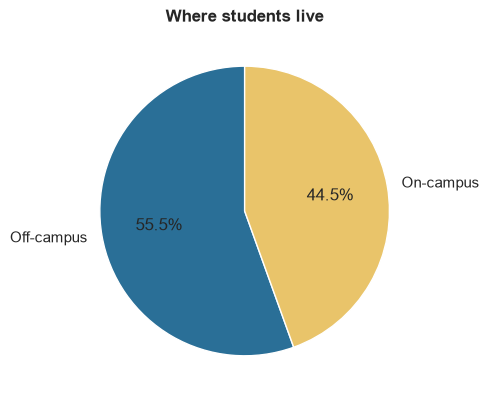

In [40]:
counts = df["residence"].value_counts()

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=["#2A6F97", "#E9C46A"], wedgeprops={"edgecolor": "white"})
ax.set_title("Where students live")
plt.tight_layout()
plt.show()

### 8.3 Heatmap (a matrix of values, e.g. correlations)
Colour shows the strength of the relationship between every pair of numerical variables.

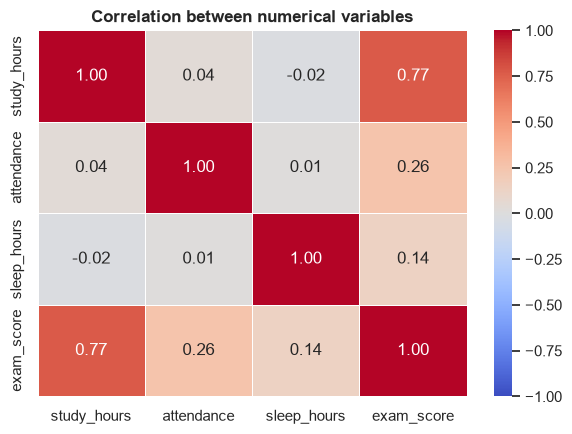

In [41]:
num_cols = ["study_hours", "attendance", "sleep_hours", "exam_score"]
corr = df[num_cols].corr()                          # correlation matrix

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title("Correlation between numerical variables")
plt.tight_layout()
plt.show()

## 9. Pandas plotting (quick plots straight from a DataFrame)
Pandas has built-in `.plot()` methods (which use Matplotlib underneath). They need only one line of code, so they are ideal for quick exploration.

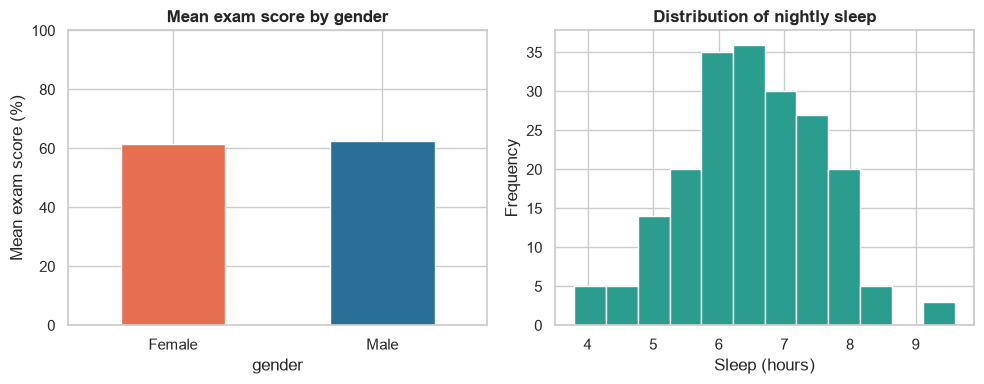

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart in one line
df.groupby("gender")["exam_score"].mean().plot(kind="bar", ax=axes[0], color=["#E76F51", "#2A6F97"])
axes[0].set_title("Mean exam score by gender")
axes[0].set_ylabel("Mean exam score (%)")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=0)

# Histogram in one line
df["sleep_hours"].plot(kind="hist", bins=12, ax=axes[1], color="#2A9D8F", edgecolor="white")
axes[1].set_title("Distribution of nightly sleep")
axes[1].set_xlabel("Sleep (hours)")

plt.tight_layout()
plt.show()

## 10. Interactive charts with Plotly
Plotly Express draws **interactive** charts: hover for exact values, zoom, pan and click legend items to hide groups. (Plotly must be installed; charts appear when you run the cells.)

In [43]:
# Interactive scatter plot: hover over a point to see the student's details
fig = px.scatter(df, x="study_hours", y="exam_score", color="program",
                 hover_data=["attendance", "sleep_hours"],
                 title="Study hours vs exam score (interactive)",
                 labels={"study_hours": "Weekly study hours", "exam_score": "Exam score (%)"})
fig.show()

NameError: name 'px' is not defined

In [ ]:
# Interactive box plot and histogram
fig = px.box(df, x="program", y="exam_score", color="program", points="all",
             title="Exam score by programme (interactive)")
fig.show()

fig = px.histogram(df, x="exam_score", nbins=15, color="gender", barmode="overlay",
                   opacity=0.7, title="Exam score distribution by gender")
fig.show()

In [ ]:
# Interactive line chart
weekly_long = weekly.melt(id_vars="week", var_name="Section", value_name="Average quiz score")
fig = px.line(weekly_long, x="week", y="Average quiz score", color="Section", markers=True,
              title="Weekly average quiz score (interactive)")
fig.show()

NameError: name 'px' is not defined

## 11. Best practice in action: honest vs misleading charts
The same data drawn two ways. Cutting the y-axis makes a tiny difference look enormous. **Always start bar charts at zero.**

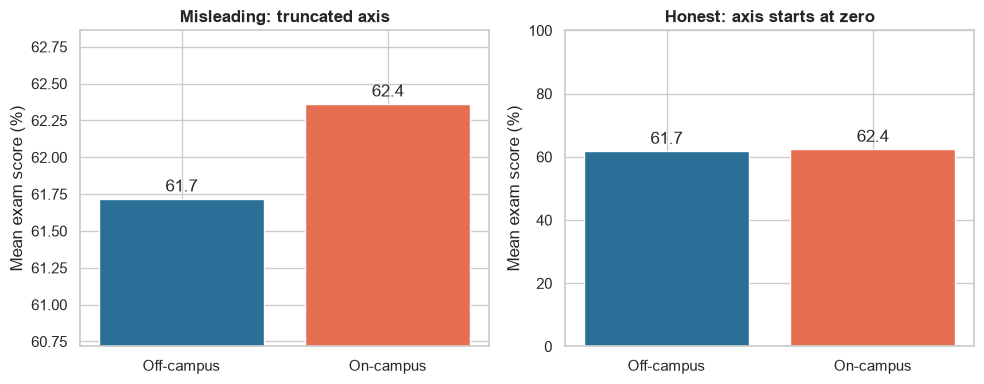

In [ ]:
res = df.groupby("residence")["exam_score"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, ylim, title in [(axes[0], (res.min() - 1, res.max() + 0.5), "Misleading: truncated axis"),
                        (axes[1], (0, 100), "Honest: axis starts at zero")]:
    bars = ax.bar(res.index, res.values, color=["#2A6F97", "#E76F51"])
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.set_ylabel("Mean exam score (%)")
plt.tight_layout()
plt.show()

## 12. Putting it together: a small dashboard
Several related charts in one figure using `plt.subplots`.

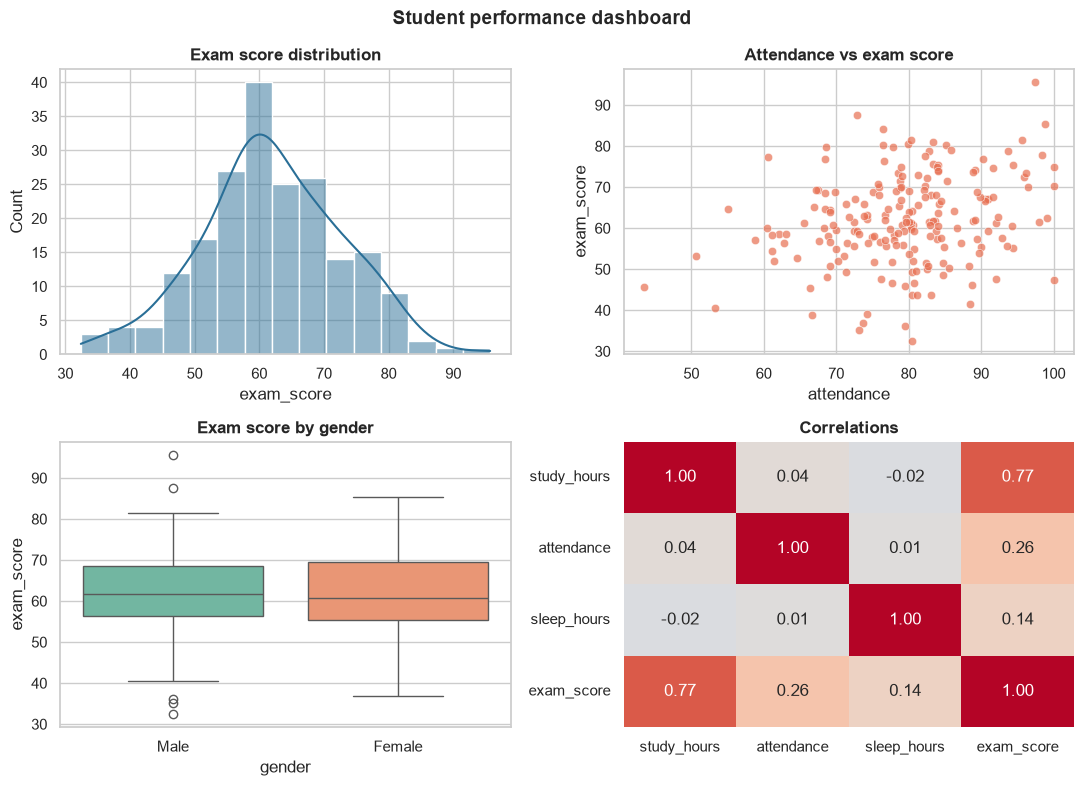

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

sns.histplot(df["exam_score"], bins=15, kde=True, color="#2A6F97", ax=axes[0, 0])
axes[0, 0].set_title("Exam score distribution")

sns.scatterplot(data=df, x="attendance", y="exam_score", alpha=0.7, color="#E76F51", ax=axes[0, 1])
axes[0, 1].set_title("Attendance vs exam score")

sns.boxplot(data=df, x="gender", y="exam_score", hue="gender", palette="Set2", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Exam score by gender")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Correlations")

fig.suptitle("Student performance dashboard", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 13. Conclusions
* **Histogram** – exam scores are roughly bell-shaped and centred near the mean.
* **Scatter plot and heatmap** – more study hours and better attendance go with higher scores (positive correlation); correlation does not by itself prove causation.
* **Box plot / bar chart** – programmes and groups differ only slightly, so no group is clearly stronger.
* **Line chart** – both sections improve week by week; Section B climbs faster.
* **Best practices** – clear titles and labels, zero-based bars, few colours and the right chart for the question make a chart honest and easy to read.

**References:** Hunter (2007) Matplotlib; Waskom (2021) seaborn; McKinney (2010) pandas; Plotly Technologies Inc. (2015); Anscombe (1973). Full details are in the report.